<img src="logo.png" alt="Vegeta" width="240">

# prop_lab — Kestrel's 9×6 propeller alone in CFD, and what it hands to the aircraft

Everything Kestrel says about its propellers rests on one assumption: Boreas's generic thin-airfoil section for a
9-inch blade. The drive tables (full thrust, torque-to-thrust, power against the inflow) are its blade-element
numbers; the propeller normal force in the transition is De Young's estimate; the rotor disks in the airframe CFD
are blade-element sources fed with the same blade rows and polar. **This notebook measures the propeller itself**:
the 9×6 resolved — blades and hub — in a rotating frame, in the configurations the aircraft flies:

| configuration | template | what Kestrel reads from it |
|---|---|---|
| the hover: static thrust at three speeds (the hover rpm among them) | `rotor_mrf_static` | thrust and power per rpm — the drive table's first row, the figure of merit |
| axial inflow 4–24 m/s at 8000 rpm, two points at 10 000, the cruise at its own rpm | `rotor_mrf` | thrust, torque, efficiency against the advance ratio — the drive tables and `rpm_for` out to the pitch speed |
| inflow at 15–90° to the axis at 8 and 14 m/s | `rotor_mrf_oblique` (new) | the **normal force** and the propeller's own pitching moment — the transition model's `prop_cn_alpha`; the thrust loss off-axis |

Each case is read beside blade-element theory at the same point. What comes out is a **calibration** — two scales
for the blade section (lift slope, profile drag) that make BEMT match the solved hover and axial cases in thrust and
torque together, and one factor on the normal-force slope — written with the whole table to
`designs/data/prop_lab.json`. `kestrel_systems.propulsion` applies the section scales (the drive tables, `rpm_for`
and the rotor disks' polar tables then carry the measured propeller), `kestrel_flight.prop_cn_alpha` the normal-force
factor; notebooks 38 and 40 say on every run whether the calibration is on file. The last section turns the same
loads into **noise** — the blade-passing frequency and its harmonics, the broadband, dB(A) at a bystander — and
renders the sound as WAV files (one rotor, the four rotors beating in the hover, the transition as a glide).

**A failure is a result.** A case that fails in a step or runs into nonsense is listed as such and left out of the
fit. Without OpenFOAM (this copy) every case is NOT RUN and the calibration stays at unity.

| variable | default | meaning |
|---|---|---|
| `VEGETA_SKIP_OPENFOAM=1` | unset | list and prepare only |
| `PROP_LAB_QUALITY` | `screening` | `screening` (6 cells per diameter, ~1 M cells, 400 iterations) or `fine` (8, ×2.5 cells, 800) |
| `PROP_LAB_JOBS` / `PROP_LAB_PROCESSORS` | 1 / 4 | cases in parallel / MPI ranks per case |
| `PROP_LAB_ONLY` | unset | `hover`, `axial`, `oblique` or a comma list |

In [1]:
import json, math, os, sys, datetime
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from vegeta import dedalus, aeromant, boreas
sys.path.insert(0, "designs")
import prop_lab as pl, kestrel_systems as ks, kestrel_flight as kf, kestrel_loop as kl

pd.set_option("display.max_colwidth", 70); pd.set_option("display.width", 230); pd.set_option("display.max_columns", 40)
RUNS = Path("_runs/prop_lab"); RUNS.mkdir(parents=True, exist_ok=True)
OUT = Path("output/41_prop_lab"); OUT.mkdir(parents=True, exist_ok=True)
RUN_CFD = os.environ.get("VEGETA_SKIP_OPENFOAM") != "1"
QUALITY = os.environ.get("PROP_LAB_QUALITY", "screening")
JOBS, PROCS = int(os.environ.get("PROP_LAB_JOBS", "1")), int(os.environ.get("PROP_LAB_PROCESSORS", "4"))
ONLY = [s.strip() for s in os.environ.get("PROP_LAB_ONLY", "hover,axial,oblique").split(",") if s.strip()]
TODAY = datetime.date.today().isoformat()
print(f"CFD {'on' if RUN_CFD else 'NOT RUN (VEGETA_SKIP_OPENFOAM=1)'} | quality {QUALITY} {pl.QUALITY[QUALITY]} | jobs {JOBS} × {PROCS} ranks | kinds {ONLY}")
CAL0 = ks.prop_lab_calibration()
print("calibration on file before this run:", CAL0 if CAL0["on_file"] else "none (unity scales)")

CFD NOT RUN (VEGETA_SKIP_OPENFOAM=1) | quality screening {'cells_per_diameter': 6.0, 'surface_level': 3, 'near_level': 2, 'rotor_level': 2, 'wake_level': 1, 'iterations': 400, 'residual_target': 0.0001} | jobs 1 × 4 ranks | kinds ['hover', 'axial', 'oblique']
calibration on file before this run: none (unity scales)


## 1. The propeller

The 9×6 as Boreas carries it (`kestrel_systems.COMPONENTS`: constant geometric pitch 152 mm, chord 14 → 21 → 8 mm,
two blades) built by Dedalus's parametric propeller — NACA-4 sections 10 % thick with 4 % camber, a 16 × 10 mm hub —
and turned onto the rotor frame's axis (+x). The real APC blade's planform and twist are not in the model: this is
the propeller Kestrel's numbers assume, measured as such.

,diameter,pitch,blades,hub_diameter,hub_height,bore,chord_root,chord_max,chord_tip,thickness,camber,stations
"the 9x6 (mm, -)",228.6,152.4,2.0,16.0,10.0,5.0,14.0,21.0,8.0,0.1,0.04,12.0


,dimensions,surface_area,volume
CAD,"[228.60000020000038, 25.56007236091198, 14.129336106180592]",8032.1,5884.4


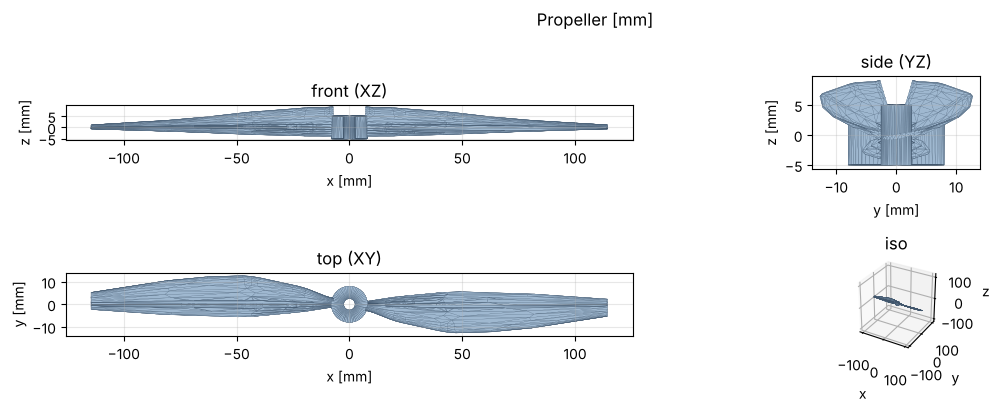

STL in the rotor frame (axis +x): _runs/prop_lab/stl/prop_9x6_axis_x.stl


,0,1,2,3,4,5,6,7,8,9,10,11
r [m],0.0137,0.0229,0.0320,0.0411,0.0503,0.0594,0.0686,0.0777,0.0869,0.0960,0.1052,0.1143
twist [deg],60.5124,46.6962,37.1578,30.5178,25.7474,22.1999,19.4775,17.3315,15.6008,14.1778,12.9886,11.9808
chord [m],0.0140,0.0158,0.0176,0.0195,0.0210,0.0202,0.0189,0.0172,0.0153,0.0131,0.0106,0.0080


In [2]:
G = pl.geometry()
display(pd.Series(G, name="the 9x6 (mm, -)").to_frame().T)
CAD = pl.cad()
display(pd.Series({k: (round(v, 1) if isinstance(v, float) else v) for k, v in CAD.measure().items() if k in ("volume", "surface_area", "dimensions")}, name="CAD").to_frame().T)
dedalus.plot_views(CAD, figsize=(12, 4)); plt.show()
STL = pl.stl(RUNS / "stl")
print("STL in the rotor frame (axis +x):", STL)
PROP = ks.propulsion().prop
BLADE = pd.DataFrame({"r [m]": PROP.r, "twist [deg]": PROP.beta_deg, "chord [m]": PROP.chord})
display(BLADE.T.round(4))

## 2. The blade-element baseline

What Boreas predicts at every configuration before any solver runs: thrust, torque, shaft power, efficiency (figure
of merit in the hover), the advance ratio — and for the oblique cases De Young's normal-force slope, the number the
transition model uses. The hover rpm (one rotor's share of the 1.69 kg aircraft) and the cruise rpm (0.8 N at
16 m/s) come from the same model.

,kind,template,rpm,V [m/s],angle [deg],J,Re (0.75 R),BEMT T [N],BEMT Q [N·m],BEMT P [W],BEMT η / FM,De Young CNα [1/rad]
"hover, 5000 rpm",hover,rotor_mrf_static,5000.0000,0.0,0.0,0.0000,36116.9466,2.2955,0.0371,19.4150,0.5649,NaN
"hover, 6723 rpm (the hover)",hover,rotor_mrf_static,6722.8949,0.0,0.0,0.0000,48562.0872,4.1500,0.0670,47.1949,0.5649,NaN
"hover, 9000 rpm",hover,rotor_mrf_static,9000.0000,0.0,0.0,0.0000,65010.5039,7.4374,0.1201,113.2280,0.5649,NaN
"axial, 4 m/s, 8000 rpm",axial,rotor_mrf,8000.0000,4.0,0.0,0.1312,57787.1145,5.4359,0.0979,81.9799,0.2652,NaN
"axial, 8 m/s, 8000 rpm",axial,rotor_mrf,8000.0000,8.0,0.0,0.2625,57787.1145,4.7011,0.0955,80.0067,0.4701,NaN
"axial, 12 m/s, 8000 rpm",axial,rotor_mrf,8000.0000,12.0,0.0,0.3937,57787.1145,3.6760,0.0854,71.5730,0.6163,NaN
"axial, 16 m/s, 8000 rpm",axial,rotor_mrf,8000.0000,16.0,0.0,0.5249,57787.1145,2.4056,0.0659,55.1832,0.6975,NaN
"axial, 20 m/s, 8000 rpm",axial,rotor_mrf,8000.0000,20.0,0.0,0.6562,57787.1145,1.0101,0.0372,31.1417,0.6487,NaN
"axial, 24 m/s, 8000 rpm",axial,rotor_mrf,8000.0000,24.0,0.0,0.7874,57787.1145,-0.6632,-0.0066,-5.5433,0.0000,NaN
"axial, 12 m/s, 10000 rpm",axial,rotor_mrf,10000.0000,12.0,0.0,0.3150,72233.8932,6.7586,0.1446,151.4185,0.5356,NaN


hover rpm 6723, cruise rpm 6562; 21 cases


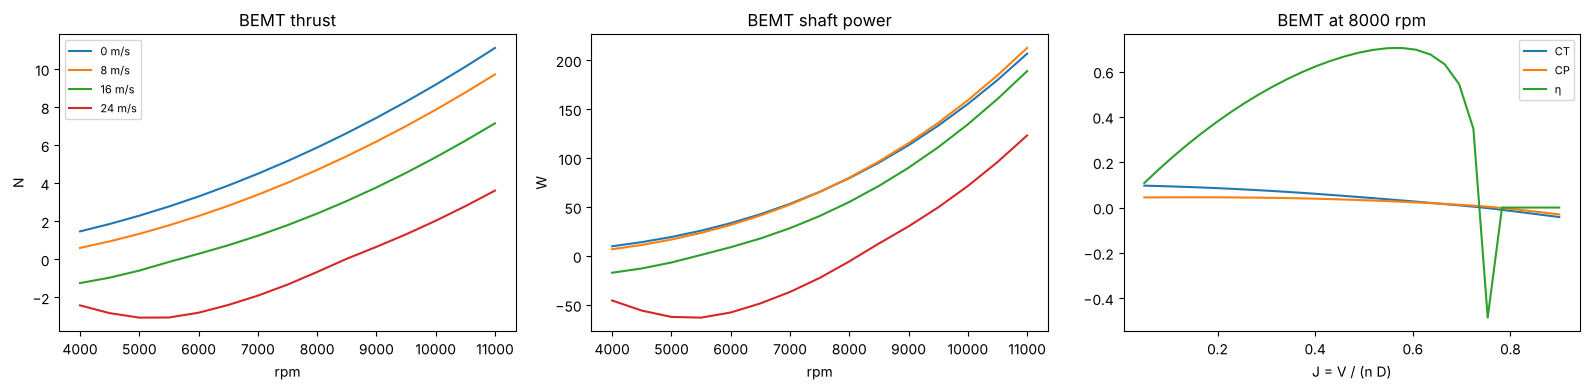

In [3]:
SPECS = {k: v for k, v in pl.configurations().items() if v["kind"] in ONLY}
T0 = pl.table(None, SPECS)
display(T0.drop(columns=["status", "note"]).astype({c: float for c in T0.columns if c not in ("kind", "template", "status", "note")}).round(4))
print(f"hover rpm {pl.rpm_hover():.0f}, cruise rpm {pl.rpm_cruise():.0f}; {len(SPECS)} cases")
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
rpms = np.linspace(4000, 11000, 15)
for V in (0.0, 8.0, 16.0, 24.0):
    ops = [pl.bemt(r, V) for r in rpms]
    ax[0].plot(rpms, [o.thrust for o in ops], label=f"{V:g} m/s"); ax[1].plot(rpms, [o.power for o in ops], label=f"{V:g} m/s")
ax[0].set(xlabel="rpm", ylabel="N", title="BEMT thrust"); ax[1].set(xlabel="rpm", ylabel="W", title="BEMT shaft power"); ax[0].legend(fontsize=8)
Js = np.linspace(0.05, 0.9, 30)
n = 8000 / 60
ops = [pl.bemt(8000.0, j * n * PROP.diameter) for j in Js]
ax[2].plot(Js, [o.ct for o in ops], label="CT"); ax[2].plot(Js, [o.cp for o in ops], label="CP"); ax[2].plot(Js, [o.efficiency for o in ops], label="η")
ax[2].set(xlabel="J = V / (n D)", title="BEMT at 8000 rpm"); ax[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

## 3. The campaign

Every case prepared (the STL, the MRF zone, the mesh and solver settings of the chosen quality), run through the
cache, read beside its blade-element row. The table is the result whatever happened in the solver.

In [4]:
TAB = T0
if RUN_CFD:
    try:
        CASES = pl.plan(RUNS, SPECS, quality=QUALITY)
        names = list(CASES)
        res = aeromant.run_cases([CASES[n] for n in names], jobs=JOBS, processors=PROCS, progress=True, cache=True)
        TAB = pl.table(dict(zip(names, res)), SPECS)
    except Exception as exc:                        # no OpenFOAM, no CAD kernel, a broken environment: the listing stays NOT RUN
        print(f"CFD not run — {type(exc).__name__}: {str(exc)[:200]}")
SM = pl.summary(TAB)
print(SM["line"])
cols = [c for c in TAB.columns if c not in ("template", "Re (0.75 R)")]
display(TAB[cols])
TAB.to_csv(OUT / "prop_lab_cases.csv")
fails = TAB[TAB["status"].isin(["FAILED", "diverged"])]
if len(fails):
    print(f"{len(fails)} cases did not solve:"); display(fails[["kind", "rpm", "V [m/s]", "angle [deg]", "status", "note"]])

0 of 21 cases solved (hover 0, axial 0, oblique 0), 0 diverged, 0 failed, 21 not run


,kind,rpm,V [m/s],angle [deg],J,BEMT T [N],BEMT Q [N·m],BEMT P [W],BEMT η / FM,De Young CNα [1/rad],status,note
"hover, 5000 rpm",hover,5000.0,0.0,0.0,0.0,2.29549,0.03708,19.414954,0.564901,NaN,NOT RUN,
"hover, 6723 rpm (the hover)",hover,6722.894902,0.0,0.0,0.0,4.15,0.067036,47.194927,0.564901,NaN,NOT RUN,
"hover, 9000 rpm",hover,9000.0,0.0,0.0,0.0,7.437389,0.120139,113.228012,0.564901,NaN,NOT RUN,
"axial, 4 m/s, 8000 rpm",axial,8000.0,4.0,0.0,0.131234,5.435932,0.097856,81.979949,0.265232,NaN,NOT RUN,
"axial, 8 m/s, 8000 rpm",axial,8000.0,8.0,0.0,0.262467,4.701054,0.095501,80.006705,0.470066,NaN,NOT RUN,
"axial, 12 m/s, 8000 rpm",axial,8000.0,12.0,0.0,0.393701,3.676018,0.085434,71.57297,0.616325,NaN,NOT RUN,
"axial, 16 m/s, 8000 rpm",axial,8000.0,16.0,0.0,0.524934,2.405637,0.06587,55.183229,0.697498,NaN,NOT RUN,
"axial, 20 m/s, 8000 rpm",axial,8000.0,20.0,0.0,0.656168,1.010119,0.037173,31.141715,0.648724,NaN,NOT RUN,
"axial, 24 m/s, 8000 rpm",axial,8000.0,24.0,0.0,0.787402,-0.663199,-0.006617,-5.543296,0.0,NaN,NOT RUN,
"axial, 12 m/s, 10000 rpm",axial,10000.0,12.0,0.0,0.314961,6.75858,0.144594,151.418536,0.535621,NaN,NOT RUN,


## 4. CFD against blade-element theory

The hover and axial cases: thrust and torque ratios against the advance ratio; the oblique cases: the normal-force
slope against De Young's and the thrust's fall-off with the angle.

In [5]:
SOL = TAB[TAB["status"] == "solved"]
if len(SOL):
    fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
    ax_ = SOL[SOL["kind"].isin(["hover", "axial"])]
    ax[0].plot(ax_["J"].astype(float), ax_["T CFD / BEMT"].astype(float), "o", label="thrust"); ax[0].plot(ax_["J"].astype(float), ax_["Q CFD / BEMT"].astype(float), "s", label="torque")
    ax[0].axhline(1, color="k", lw=0.8); ax[0].set(xlabel="J", ylabel="CFD / BEMT", title="hover and axial inflow"); ax[0].legend(fontsize=8)
    ob = SOL[SOL["kind"] == "oblique"]
    if len(ob):
        for V, g in ob.groupby("V [m/s]"):
            ax[1].plot(g["angle [deg]"].astype(float), g["CFD CNα [1/rad]"].astype(float), "o-", label=f"CFD, {V:g} m/s")
            ax[1].plot(g["angle [deg]"].astype(float), g["De Young CNα [1/rad]"].astype(float), "--", label=f"De Young, {V:g} m/s")
            ax[2].plot(g["angle [deg]"].astype(float), g["T CFD / BEMT"].astype(float), "o-", label=f"{V:g} m/s")
        ax[1].set(xlabel="inflow angle [deg]", ylabel="dCN/dα [1/rad]", title="the propeller's normal force"); ax[1].legend(fontsize=7)
        ax[2].set(xlabel="inflow angle [deg]", ylabel="T CFD / BEMT (axial component)", title="thrust off-axis"); ax[2].legend(fontsize=8)
    plt.tight_layout(); plt.show()
else:
    print("nothing solved: the plots wait for a run with OpenFOAM")

nothing solved: the plots wait for a run with OpenFOAM


## 5. The calibration, and what Kestrel reads

Two scales on the blade section — the lift slope and the profile drag — fitted so that blade-element theory
reproduces the solved hover and axial cases in thrust **and** torque (a least-squares fit on the log ratios), and the
median of the measured normal-force slope over De Young's. Exported to `designs/data/prop_lab.json`; then the drive
table rebuilt on the calibrated section against the one Kestrel used so far.

In [6]:
SEC, NF = pl.fit_section(TAB), pl.fit_normal_force(TAB)
display(pd.Series({k: v for k, v in SEC.items()}, name="section fit").to_frame().T)
display(pd.Series({k: v for k, v in NF.items() if k != "points"}, name="normal-force fit").to_frame().T)
DOC = pl.export(TAB, pl.PROP_LAB_JSON, meta={"source": "41_prop_lab", "quality": QUALITY, "date": TODAY, "propeller": "9x6, Dedalus CAD of Boreas's planform"})
CAL = ks.prop_lab_calibration()
print("calibration on file now:", CAL)
CHK = [kl.check("hover cases solved", SM["by kind"]["hover"], "≥", 2), kl.check("axial cases solved", SM["by kind"]["axial"], "≥", 5),
       kl.check("oblique cases solved", SM["by kind"]["oblique"], "≥", 4),
       kl.check("section fit: rms log ratio after", SEC["rms_log_ratio_after"] if SEC["rms_log_ratio_after"] is not None else float("nan"), "≤", 0.1, note="thrust and torque within ~10 % together"),
       kl.check("cl scale within", abs((SEC["cl_scale"] or 1.0) - 1.0), "≤", 0.3, note="further than this and the generic section is the wrong model, not a scaled one"),
       kl.check("cn factor within", abs((NF["cn_factor"] or 1.0) - 1.0), "≤", 0.5)]
display(kl.check_table(CHK, "the campaign"))
if CAL["on_file"]:
    DR = ks.drive_table(recompute=True, save=True)         # the drive table on the calibrated section (the key stamps the scales)
    print("drive table rebuilt on the calibrated section:", DR.source, "| T_max at 0 / 16 m/s:", round(DR.T_max[0], 2), round(float(DR.t_max(16.0)), 2), "N")
    hp = ks.hover_point(1.686)
    print(f"hover: {hp['rpm']:.0f} rpm, {hp['electrical_W']:.0f} W per drive, T/W {hp['T_W']:.2f}")
else:
    print("no calibration yet: Kestrel's drive tables and normal force stay on the generic section (unity scales)")

,cl_scale,cd_scale,n_cases,rms_log_ratio_before,rms_log_ratio_after
section fit,NaN,NaN,0.0,NaN,NaN


,cn_factor,n_cases
normal-force fit,NaN,0.0


calibration on file now: {'cl_scale': 1.0, 'cd_scale': 1.0, 'cn_factor': 1.0, 'on_file': False, 'meta': {'source': '41_prop_lab', 'quality': 'screening', 'date': '2026-10-16', 'propeller': "9x6, Dedalus CAD of Boreas's planform"}}


the campaign,value,target,holds,note
check,,,,
hover cases solved,0,≥ 2,✘,
axial cases solved,0,≥ 5,✘,
oblique cases solved,0,≥ 4,✘,
section fit: rms log ratio after,nan,≤ 0.1,✘,thrust and torque within ~10 % together
cl scale within,0,≤ 0.3,✔,"further than this and the generic section is the wrong model, not ..."
cn factor within,0,≤ 0.5,✔,


no calibration yet: Kestrel's drive tables and normal force stay on the generic section (unity scales)


## 6. Noise: the frequencies, and what it sounds like

The **blade-passing frequency** is B·n — two blades at the hover's 6700 rpm give 224 Hz, the cruise's lower rpm a
lower note, 10 000 rpm 333 Hz — and the tonal noise of the steady blade loading (Gutin: the thrust and torque the CFD
measured, BEMT's where it did not) sits on it and its harmonics; the broadband vortex noise (Hubbard's estimate from
the blade area and the section speed at 0.7 R) peaks higher, around the Strouhal frequency of the blade's thickness.
Both at a bystander 10 m off, 60° from the axis, in dB and dB(A). A steady estimate: the once-per-revolution load cycle
of an inclined inflow adds loading harmonics it does not carry — the oblique cases' loads are the mean ones.

Then the sound itself, rendered: one rotor in the hover, in cruise, at a transition point; the **four rotors in the
hover** — the allocation holds the heading with a small split between the diagonal pairs, so the four blade-passing
tones beat against each other rather than hum; and the **transition** as a glide from the hover rpm through the
oblique points to the cruise. One full scale for every file: the louder case is louder on playback.

,source,rpm,V [m/s],angle [deg],BPF [Hz],tone 1 [dB],tone 2 [dB],tone 3 [dB],tonal [dB],broadband [dB],broadband peak [Hz],total [dB],total [dB(A)]
"hover, 5000 rpm",BEMT,5000.0,0.0,0.0,166.7,26.9,-1.2,-30.6,26.9,28.8,4140.7,31.0,29.8
"hover, 6723 rpm (the hover)",BEMT,6722.9,0.0,0.0,224.1,34.9,11.9,-12.4,35.0,36.5,5567.5,38.8,37.1
"hover, 9000 rpm",BEMT,9000.0,0.0,0.0,300.0,40.7,22.7,3.3,40.8,44.1,7453.3,45.8,43.8
"axial, 4 m/s, 8000 rpm",BEMT,8000.0,4.0,0.0,266.7,40.5,20.5,-0.9,40.5,41.1,6636.9,43.8,41.4
"axial, 8 m/s, 8000 rpm",BEMT,8000.0,8.0,0.0,266.7,41.5,21.5,0.1,41.6,41.2,6672.2,44.4,41.6
"axial, 12 m/s, 8000 rpm",BEMT,8000.0,12.0,0.0,266.7,41.6,21.6,0.2,41.7,41.5,6730.5,44.6,41.8
"axial, 16 m/s, 8000 rpm",BEMT,8000.0,16.0,0.0,266.7,40.3,20.3,-1.1,40.4,41.8,6811.3,44.1,41.9
"axial, 20 m/s, 8000 rpm",BEMT,8000.0,20.0,0.0,266.7,36.6,16.6,-4.8,36.7,42.2,6913.8,43.2,41.9
"axial, 24 m/s, 8000 rpm",BEMT,8000.0,24.0,0.0,266.7,-506.0,-506.0,-506.0,-506.0,42.6,7037.0,42.6,42.1
"axial, 12 m/s, 10000 rpm",BEMT,10000.0,12.0,0.0,333.3,47.1,30.8,13.2,47.2,47.1,8365.9,50.2,47.0


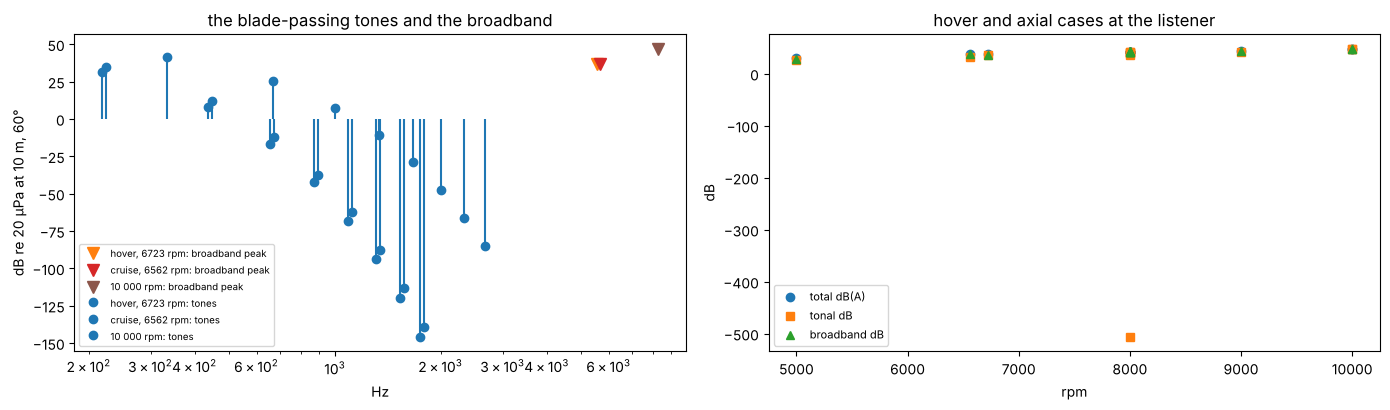

one_rotor_hover: 3 s, 39 dB rms at the listener — 37 dB(A) — output/41_prop_lab/sound/one_rotor_hover.wav


one_rotor_cruise_16ms: 3 s, 38 dB rms at the listener — 37 dB(A) — output/41_prop_lab/sound/one_rotor_cruise_16ms.wav


one_rotor_transition_8ms_45deg: 3 s, 44 dB rms at the listener — output/41_prop_lab/sound/one_rotor_transition_8ms_45deg.wav


four_rotors_hover: 3 s, 44 dB rms at the listener — four rotors at 6760, 6659, 6659, 6760 rpm, beating at 3.4 Hz — output/41_prop_lab/sound/four_rotors_hover.wav


transition_hover_to_cruise: 6 s, 43 dB rms at the listener — output/41_prop_lab/sound/transition_hover_to_cruise.wav


the transition glide (embedded):


JSON report: /home/user/vegeta/notebooks/designs/data/reports/41_prop_lab.json (22.8 kB) | JSON dossier: /home/user/vegeta/notebooks/designs/data/kestrel_dossier.json (222.3 kB) | Markdown: /home/user/vegeta/notebooks/designs/data/reports/41_prop_lab.md
<!-- /home/user/vegeta/notebooks/designs/data/reports/41_prop_lab.md -->
# prop_lab — notebook 41, the 9x6 alone

*41_prop_lab — exported 2026-10-16 12:30*

| key | value |
|---|---|
| date | 2026-10-16 |
| quality | screening |


## settings

| key | value |
|---|---|
| CFD | NOT RUN |
| quality | screening |
| kinds | hover, axial, oblique |


## the 9x6

| key | value |
|---|---|
| diameter | 229 |
| pitch | 152 |
| blades | 2 |
| hub_diameter | 16 |
| hub_height | 10 |
| bore | 5 |
| chord_root | 14 |
… 142 more lines in /home/user/vegeta/notebooks/designs/data/reports/41_prop_lab.md


'<!-- /home/user/vegeta/notebooks/designs/data/reports/41_prop_lab.md -->\n# prop_lab — notebook 41, the 9x6 alone\n\n*41_prop_lab — exported 2026-10-16 12:30*\n\n| key | value |\n|---|---|\n| date | 2026-10-16 |\n| quality | screening |\n\n\n## settings\n\n| key | value |\n|---|---|\n| CFD | NOT RUN |\n| quality | screening |\n| kinds | hover, axial, oblique |\n\n\n## the 9x6\n\n| key | value |\n|---|---|\n| diameter | 229 |\n| pitch | 152 |\n| blades | 2 |\n| hub_diameter | 16 |\n| hub_height | 10 |\n| bore | 5 |\n| chord_root | 14 |\n… 142 more lines in /home/user/vegeta/notebooks/designs/data/reports/41_prop_lab.md'

In [7]:
from IPython.display import Audio
NZ = pl.noise_table(TAB)
display(NZ.astype({c: float for c in NZ.columns if c not in ("source",)}).round(1))
NZ.to_csv(OUT / "prop_lab_noise.csv")
r_h = pl.rpm_hover()
HOV = pl.noise(r_h, 0.0, pl.bemt(r_h).thrust, pl.bemt(r_h).torque)
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
for nz, lab in ((HOV, f"hover, {r_h:.0f} rpm"), (pl.noise(pl.rpm_cruise(), 16.0, pl.bemt(pl.rpm_cruise(), 16.0).thrust, pl.bemt(pl.rpm_cruise(), 16.0).torque), f"cruise, {pl.rpm_cruise():.0f} rpm"),
                (pl.noise(10000.0, 0.0, pl.bemt(10000.0).thrust, pl.bemt(10000.0).torque), "10 000 rpm")):
    f = [t[0] for t in nz["tones"]]; L = [t[1] for t in nz["tones"]]
    ax[0].stem(f, L, label=f"{lab}: tones", basefmt=" "); ax[0].plot(nz["broadband_peak_hz"], nz["broadband_db"], "v", ms=9, label=f"{lab}: broadband peak")
ax[0].set(xlabel="Hz", ylabel="dB re 20 µPa at 10 m, 60°", title="the blade-passing tones and the broadband", xscale="log"); ax[0].legend(fontsize=7)
rows = NZ[NZ["angle [deg]"].astype(float) == 0.0]
ax[1].plot(rows["rpm"].astype(float), rows["total [dB(A)]"].astype(float), "o", label="total dB(A)"); ax[1].plot(rows["rpm"].astype(float), rows["tonal [dB]"].astype(float), "s", label="tonal dB")
ax[1].plot(rows["rpm"].astype(float), rows["broadband [dB]"].astype(float), "^", label="broadband dB"); ax[1].set(xlabel="rpm", ylabel="dB", title="hover and axial cases at the listener"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()
SOUND = pl.render(OUT / "sound", TAB, mass_kg=1.686)
for name, f in SOUND.items():
    extra = f" — {f['total_dba']:.0f} dB(A)" if "total_dba" in f else (f" — four rotors at {', '.join(f'{r:.0f}' for r in f['rpms'])} rpm, beating at {f['beat_hz'][0]:.1f} Hz" if "rpms" in f else "")
    print(f"{name}: {f['seconds']:.0f} s, {f['rms_db']:.0f} dB rms at the listener{extra} — {f['path']}")
    display(Audio(url=str(f["path"])))                     # linked, not embedded
print("the transition glide (embedded):"); display(Audio(str(SOUND["transition_hover_to_cruise"]["path"])))

# ---- the design dossier: every number of this notebook as Markdown to paste into a conversation (kestrel_report)
import kestrel_report as kr
def _g(n):
    return globals().get(n)
def _chk(names):
    import pandas as pd
    out = {}
    for n in names:
        c = _g(n)
        if c:
            out[n] = kl.check_table(c, n)
    return out

REPORT = {"settings": {"CFD": "on" if RUN_CFD else "NOT RUN", "quality": QUALITY, "kinds": ", ".join(ONLY)}, "the 9x6": G, "blade rows (Boreas)": BLADE.T,
          "rpm": {"hover": pl.rpm_hover(), "cruise": pl.rpm_cruise()}, "cases: CFD against BEMT": TAB[cols], "campaign": {k: v for k, v in SM.items() if k != "line"},
          "section fit": SEC, "normal-force fit": {k: v for k, v in NF.items() if k != "points"}, "calibration on file": CAL, "noise at the listener": NZ,
          "sound files": pd.DataFrame(SOUND).T, "checks": kl.check_table(CHK, "the campaign")}
EXP = kr.export("41_prop_lab", "prop_lab — notebook 41, the 9x6 alone", REPORT, meta={"date": TODAY, "quality": QUALITY})
print("JSON report:", EXP["json"], f"({EXP['json_kB']} kB) | JSON dossier:", EXP["dossier_json"], f"({EXP['dossier_json_kB']} kB) | Markdown:", EXP["markdown"])
kr.paste("41_prop_lab", max_lines=30)

## 7. Findings

*(written after the first pass, without OpenFOAM)* 21 cases listed and prepared — three hover speeds (5000, the hover's
6723, 9000 rpm), nine axial points out to the pitch speed with the cruise's own 6562 rpm among them, nine inflow
angles at 8 and 14 m/s — none solved, the calibration at unity. Kestrel's drive tables, `rpm_for`, the rotor disks'
polar and the propeller normal force therefore still stand on Boreas's generic blade section and De Young's estimate.
Run this notebook where OpenFOAM is installed (an hour at screening quality for the hover and axial cases, the oblique
ones about as long again); the calibration it writes is read by notebooks 38 and 40 on their next run — the hover
thrust-to-weight, the cruise power, the thrust-limited maximum speed and the transition's propeller normal force all
move with it. The first thing to read in the result: the thrust and torque ratios against J — if they drift with J
rather than sit at one level, the generic section's shape, not its scale, is wrong, and the blade's own section
(Zephyr on the real APC profile) is the next step.

**The noise, on the blade-element loads.** The blade-passing frequency is 224 Hz in the hover (219 in cruise, 333 at
10 000 rpm); the four rotors of the aircraft, their diagonal pairs split 1.5 % by the allocation, run at 6760 and
6659 rpm and **beat at 3.4 Hz** — the throb a quadrotor hover has, rendered in `four_rotors_hover.wav`. The levels
the steady models give at a bystander 10 m off — 37 dB(A) for one rotor, 44 dB for the four — are the floor, not the
sound: Gutin's steady loading and Hubbard's broadband are known to sit well under what small propellers make, where the
unsteady loading (an inclined inflow, the wake of the wing ahead, turbulence) and the trailing-edge broadband
dominate; the measured loads from the oblique cases will raise the tones, not close that gap. Read the files for the
frequencies and their relations (the glide from 224 to 219 Hz through the transition, the beats), not for loudness.